# Training demo: layer-wise cross-modal fusion GNN

A short, fully documented run of the pipeline in Fig. 6 of the report:
**load → validate → clean → normalize → train → evaluate**, for the proposed model and the GraphSAGE baseline.

This notebook uses a few epochs to show that every stage works end to end. The full experiments
(30 epochs, 3 seeds, all baselines) are run with `run_experiment.py` (see README).

## 1. Setup

In [1]:
import os, sys, time
import numpy as np
import pandas as pd
import torch

sys.path.insert(0, os.path.abspath(".."))      # make the src package importable from notebooks/
from src.config import Config
from src.data import load_raw, validate, load_dataset
from src.models import build_model, count_parameters
from src.train import train_model
from src.evaluate import evaluate_on_test
from src.plots import plot_training_curves

print("PyTorch", torch.__version__, "| CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch 2.1.2 | CUDA available: True
GPU: NVIDIA GeForce RTX 4060


## 2. Configuration

All settings come from `src/config.py` (the hyperparameter table of the report). Only the number of
epochs is reduced for this demonstration. Change `data_dir` if your datasets are elsewhere.

In [2]:
cfg = Config(dataset="ele-fashion", feature="clip", epochs=5, seeds=[0],
             data_dir=os.path.expanduser("~/mm-graph-benchmark/data"),
             results_dir="../results", figures_dir="../figures",
             device="cuda" if torch.cuda.is_available() else "cpu")
cfg

Config(data_dir='/home/Tayyab/mm-graph-benchmark/data', results_dir='../results', figures_dir='../figures', device='cuda', dataset='ele-fashion', feature='clip', fp16_features=False, hidden_dim=128, num_layers=3, dropout=0.5, use_layer_norm=True, gat_heads=4, num_neighbors=15, batch_size=128, infer_batch_size=1024, epochs=5, lr=0.001, weight_decay=0.0005, modality_dropout=0.15, edge_dropout=0.15, class_weighted_loss=False, seeds=[0])

## 3. Data validation (Section III-B)

Data-quality checks on the raw files. `True` = passed, `False` = failed, empty = information only.

In [3]:
raw = load_raw(cfg.data_dir, cfg.dataset, cfg.feature)
pd.DataFrame(validate(raw))

,check,result,ok
0,train/val overlap (nodes),0,True
1,train/test overlap (nodes),0,True
2,val/test overlap (nodes),0,True
3,repeated nodes inside a split,0,True
4,"split indices within [0, N)",0..97765 of 97766,True
5,split ratio train/val/test (%),60/10/30,None
6,nodes outside all splits (not used for trainin...,0,None
7,"edge endpoints outside [0, N)",0,True
8,edges in file,199602,None
9,self-loops (removed during cleaning),16,None


## 4. Load, clean and normalize

Removes self-loops and duplicate edges, makes the graph undirected and L2-normalizes the text and image
halves separately (the EDA showed scale differences of up to 100x).

In [4]:
del raw
data = load_dataset(cfg)
print("feature width:", data.graph.ndata["feat"].shape[1], "| text half:", data.text_dim)

ele-fashion [clip]: 97,766 nodes | 199,586 undirected edges | 11 classes present (ids 0..11) | train/val/test 58,659/9,777/29,330
feature width: 1024 | text half: 512


## 5. Train and evaluate

For each model: train with neighbor sampling, modality dropout and edge dropout, keep the
best-validation weights, then evaluate on the test set **once**.

- `fusion`: proposed model, fusion at every layer
- `late`: same two streams, fusion only at the output
- `sage`: GraphSAGE on the concatenated features (early fusion)

In [5]:
rows, histories = [], {}
in_dim = data.graph.ndata["feat"].shape[1]
for name in ["fusion", "late", "sage"]:
    print(f"\n=== {name}")
    model = build_model(name, in_dim, data.text_dim, data.num_classes, cfg).to(cfg.device)
    trained = train_model(model, data, cfg, seed=0)
    model.load_state_dict(trained["best_state"])
    test = evaluate_on_test(model, data, cfg)
    histories[name] = [trained["history"]]
    rows.append({"model": name, "test accuracy": test["accuracy"], "test macro-F1": test["macro_f1"],
                 "best epoch": trained["best_epoch"], "parameters": count_parameters(model),
                 "s / epoch": np.mean([h["epoch_time"] for h in trained["history"]]),
                 "inference (us / node)": test["inference_us_per_node"],
                 "peak GPU memory (GB)": trained["peak_memory_gb"]})
    del model
results = pd.DataFrame(rows)
results.round(4)


=== fusion
  epoch 00 | loss 0.7703 | val acc 0.8425 | 4.8s
  epoch 01 | loss 0.5550 | val acc 0.8562 | 3.9s
  epoch 02 | loss 0.5176 | val acc 0.8574 | 3.9s
  epoch 03 | loss 0.4952 | val acc 0.8595 | 3.9s
  epoch 04 | loss 0.4778 | val acc 0.8622 | 3.8s

=== late
  epoch 00 | loss 0.8018 | val acc 0.8410 | 3.5s
  epoch 01 | loss 0.5877 | val acc 0.8513 | 3.5s
  epoch 02 | loss 0.5481 | val acc 0.8565 | 3.5s
  epoch 03 | loss 0.5231 | val acc 0.8592 | 3.4s
  epoch 04 | loss 0.5018 | val acc 0.8604 | 3.4s

=== sage
  epoch 00 | loss 0.8714 | val acc 0.8391 | 2.6s
  epoch 01 | loss 0.6038 | val acc 0.8508 | 2.6s
  epoch 02 | loss 0.5532 | val acc 0.8539 | 2.6s
  epoch 03 | loss 0.5293 | val acc 0.8574 | 2.6s
  epoch 04 | loss 0.5161 | val acc 0.8605 | 2.6s


,model,test accuracy,test macro-F1,best epoch,parameters,s / epoch,inference (us / node),peak GPU memory (GB)
0,fusion,0.8629,0.6899,4,333324,4.0788,8.7212,0.5697
1,late,0.8626,0.6901,4,333324,3.4749,8.5085,0.5718
2,sage,0.8609,0.6580,4,330380,2.5982,5.6802,0.5654


## 6. Training curves

saved ../figures/demo_curves.png / .pdf


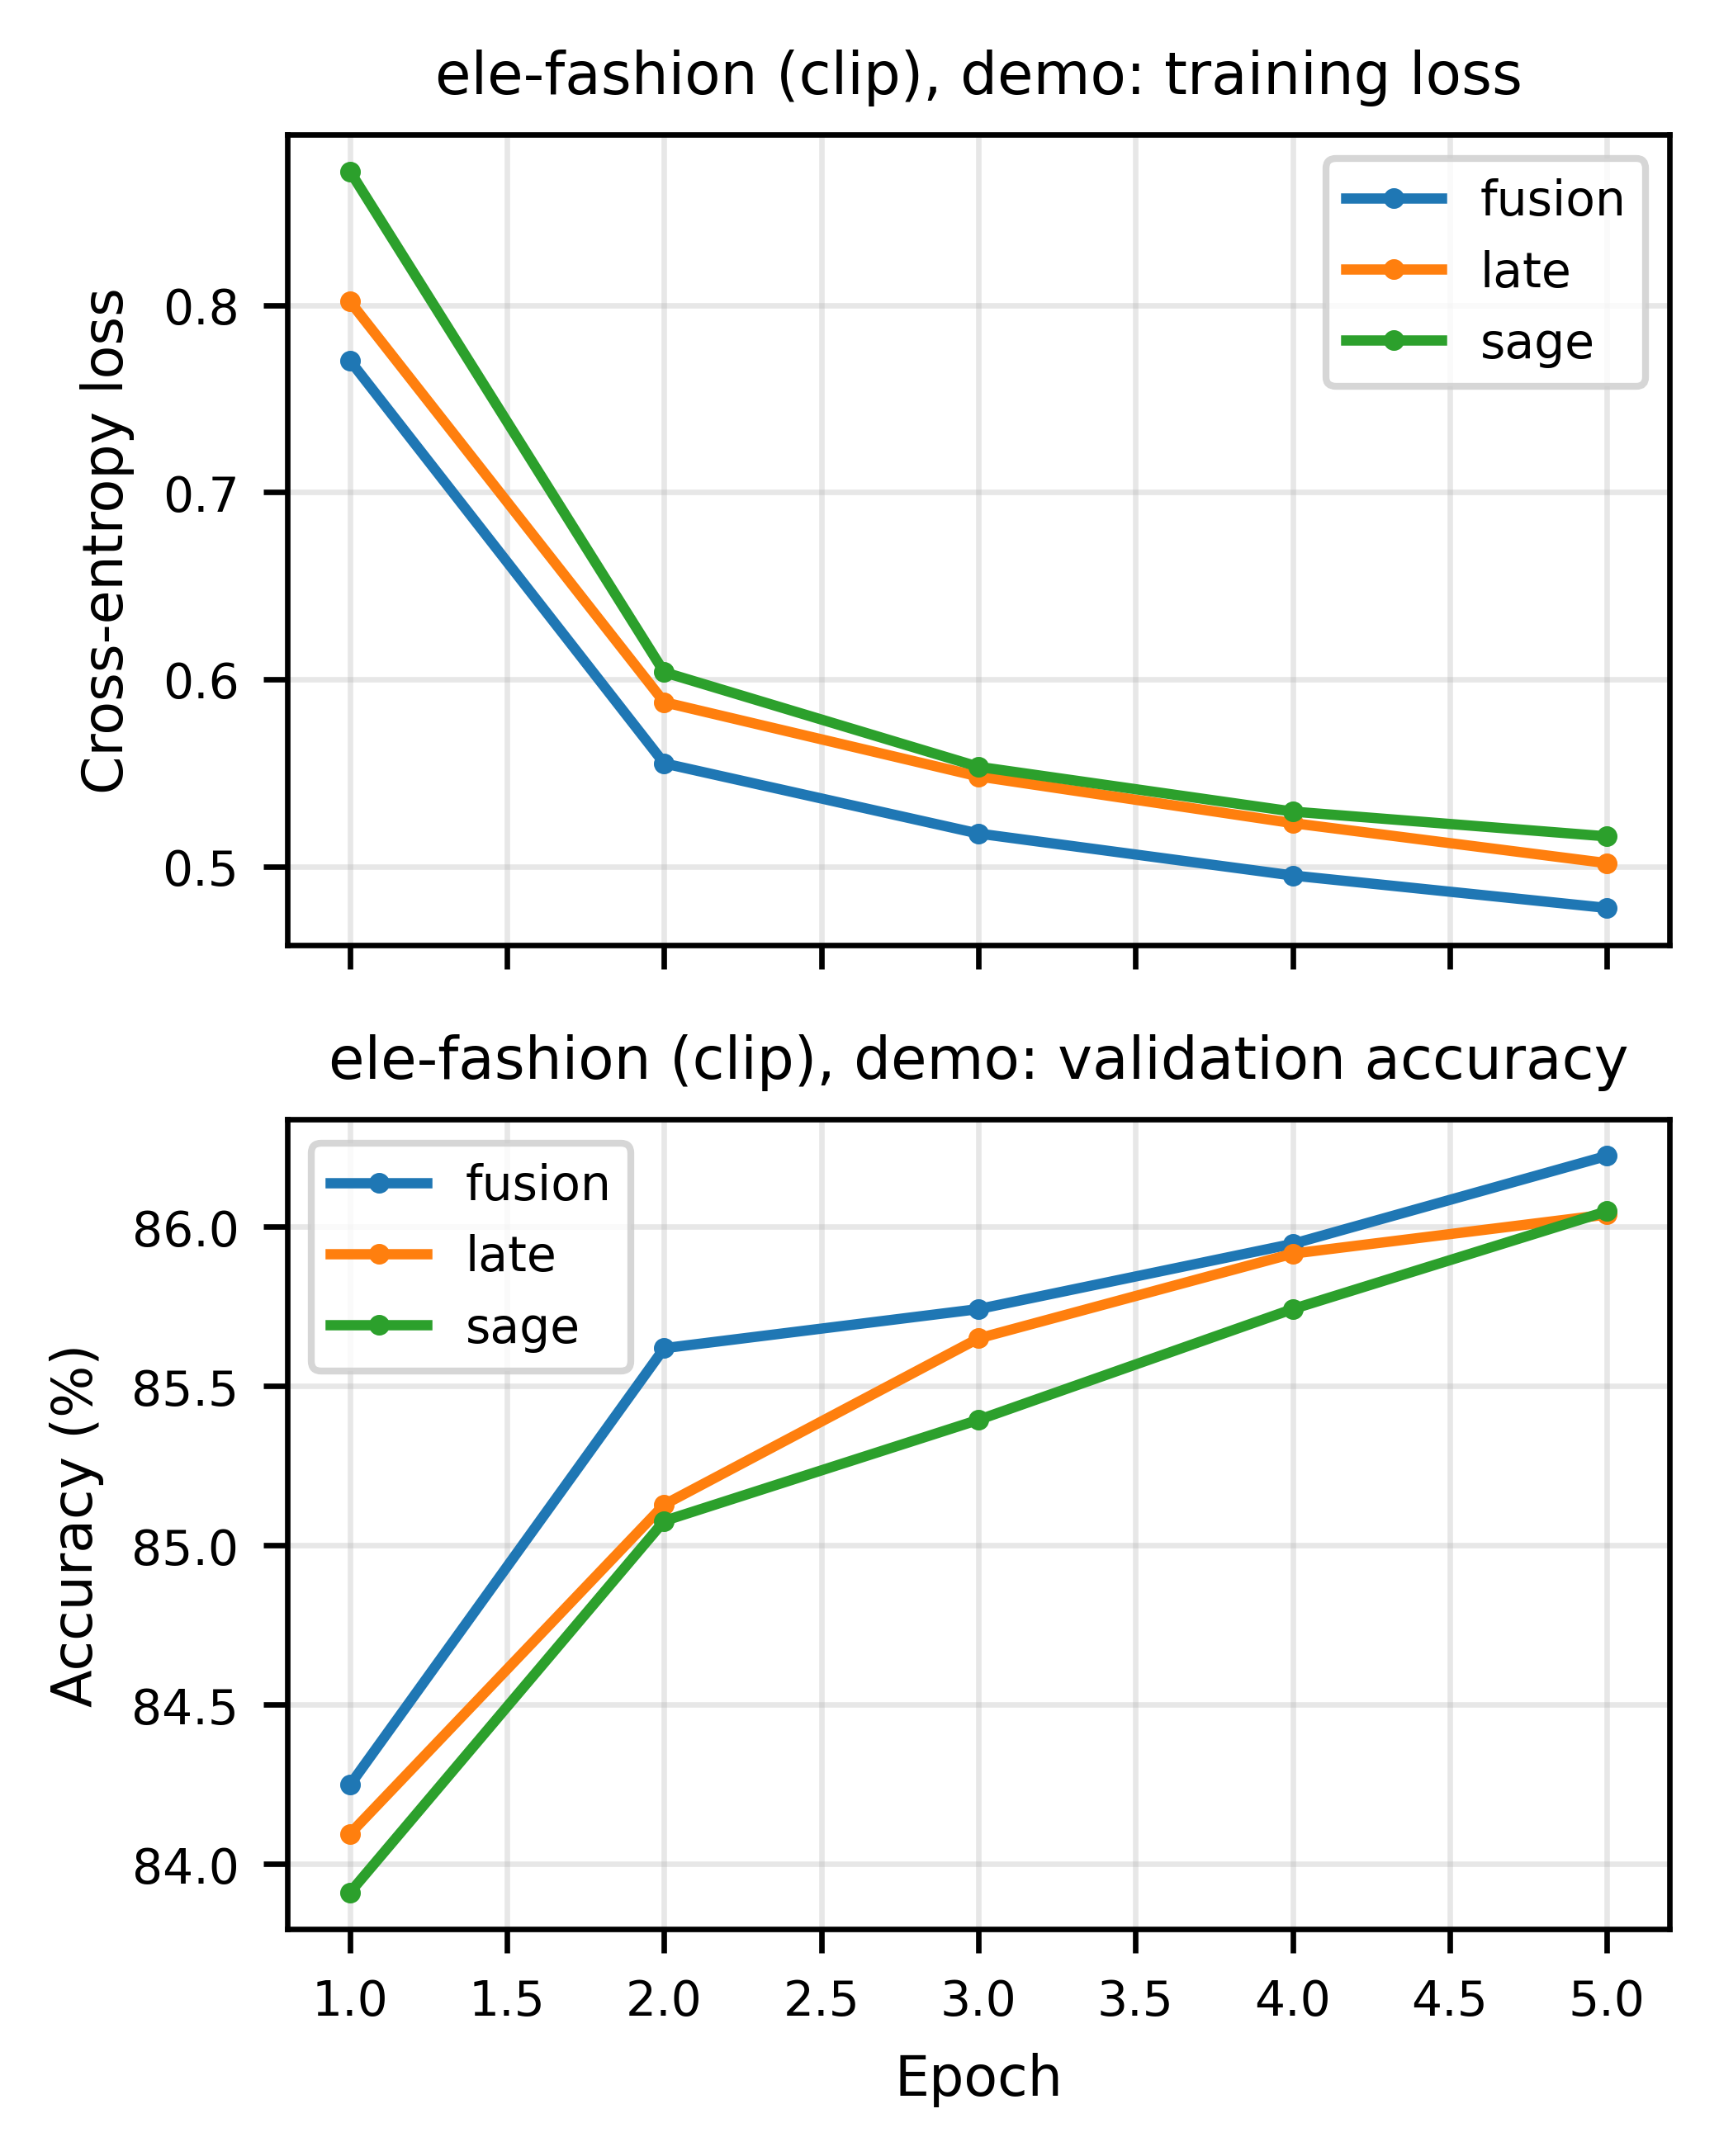

In [6]:
plot_training_curves(histories, f"{cfg.dataset} ({cfg.feature}), demo", "../figures/demo_curves")
from IPython.display import Image
Image("../figures/demo_curves.png", width=420)

## 7. Notes

- These are **demonstration** numbers from a few epochs and one seed; they are not the final results.
- Full experiments: `python run_experiment.py --dataset ele-fashion --feature clip --models fusion late sage gcn gat`
  (30 epochs, seeds 0, 1, 2).